In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("Wholesale customers data - Wholesale customers data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Saving Wholesale customers data - Wholesale customers data.csv to Wholesale customers data - Wholesale customers data.csv
Dataset loaded successfully!
Shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
# Dataset information
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing numeric values with the median
df.fillna(df.median(numeric_only=True), inplace=True)

print("\nCleaned dataset shape:", df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB

Missing values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Duplicate rows: 0

Cleaned dataset shape: (440, 8)


In [4]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


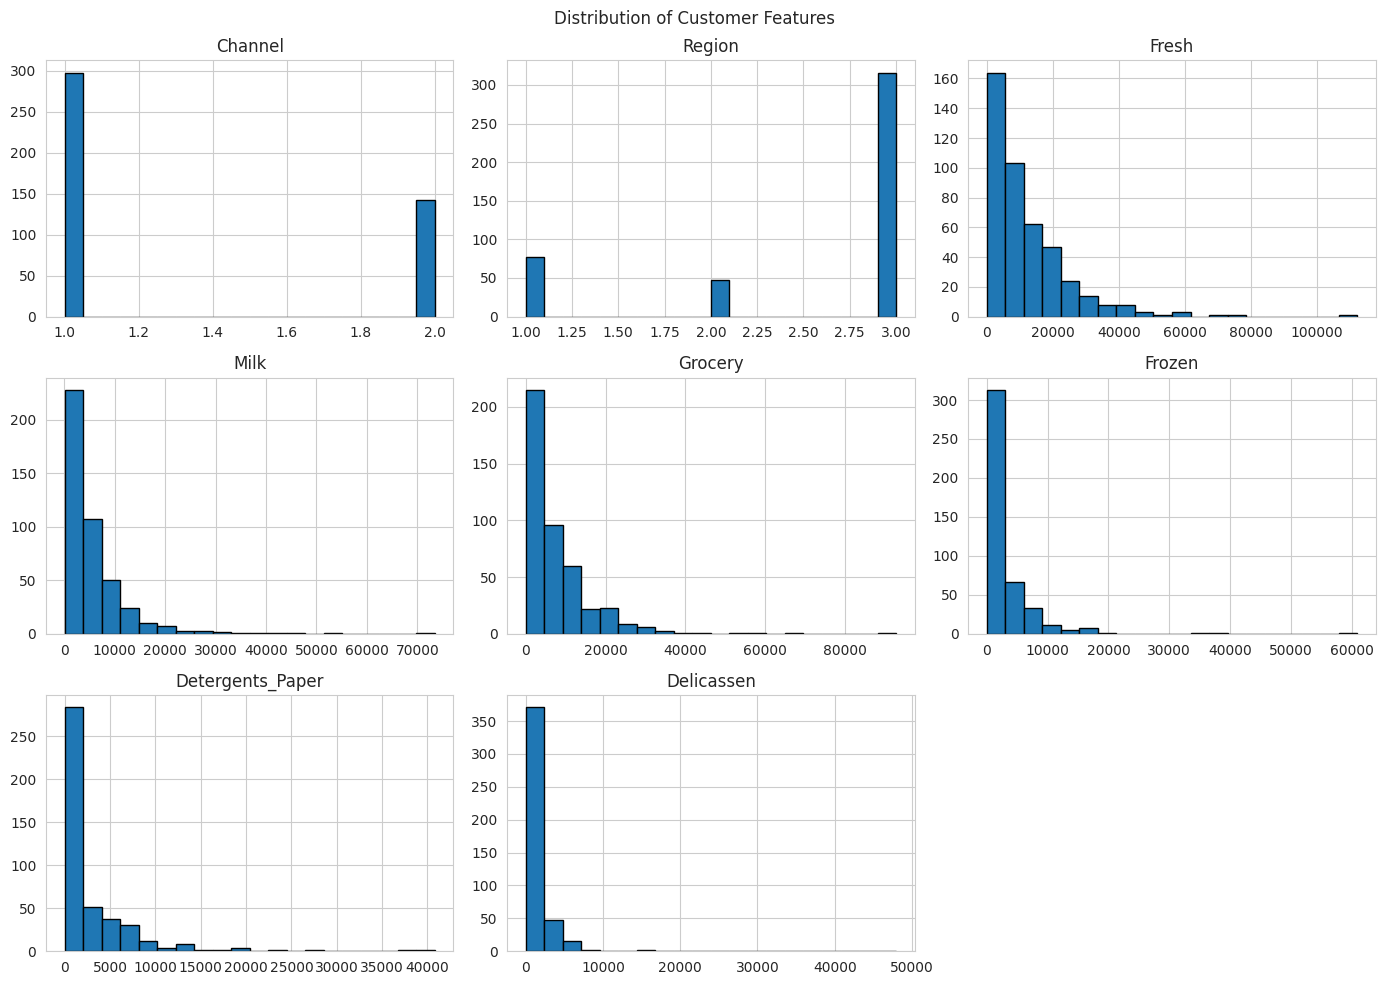

In [5]:
df.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distribution of Customer Features")
plt.tight_layout()
plt.show()

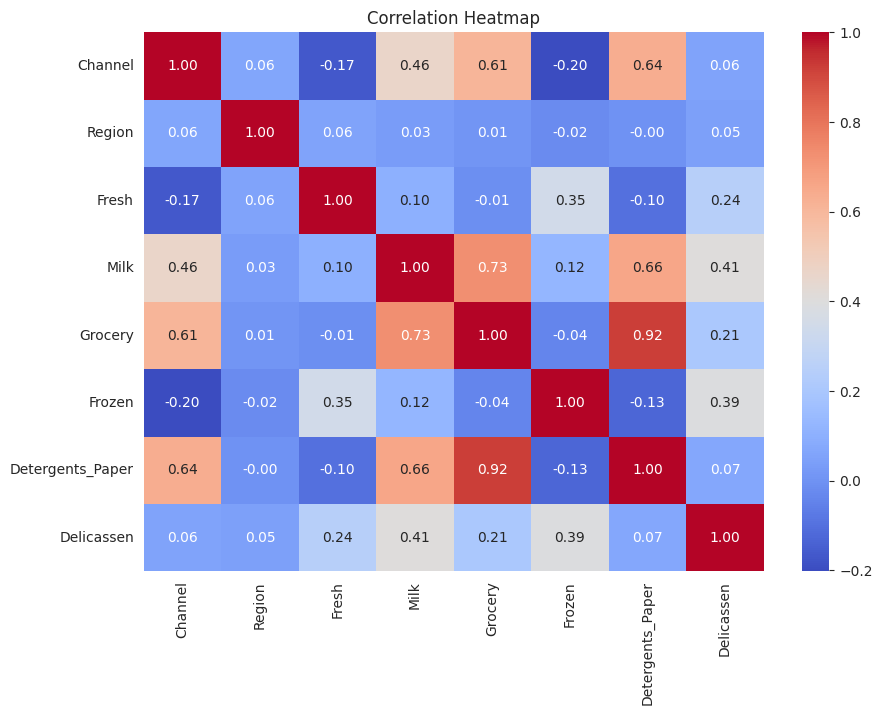

In [6]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

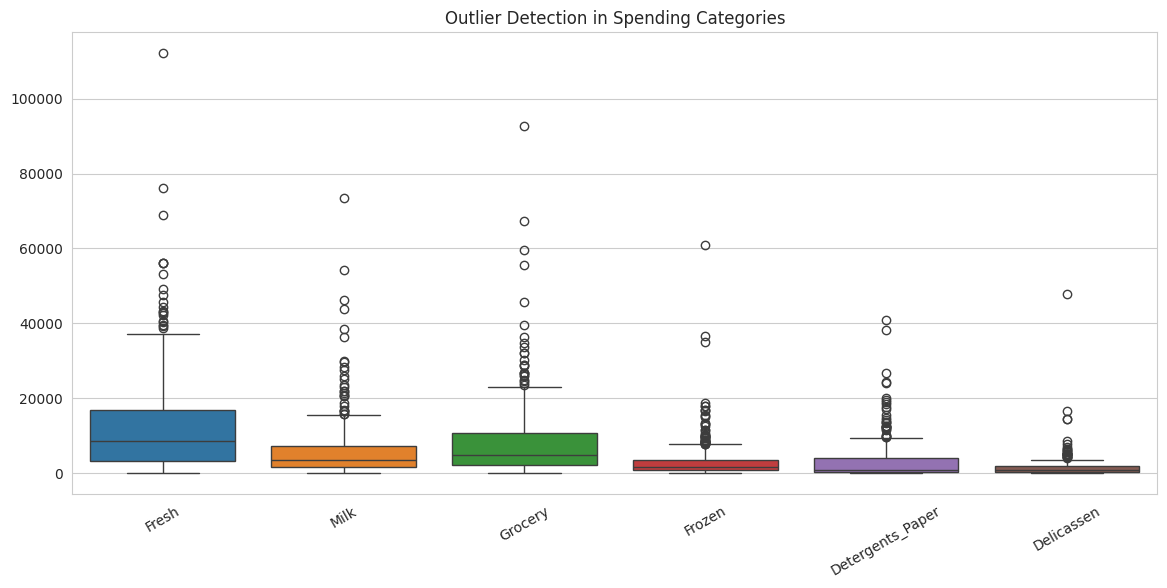

In [7]:
spending_columns = [
    "Fresh", "Milk", "Grocery",
    "Frozen", "Detergents_Paper", "Delicassen"
]

plt.figure(figsize=(14, 6))

sns.boxplot(data=df[spending_columns])

plt.title("Outlier Detection in Spending Categories")
plt.xticks(rotation=30)
plt.show()

In [8]:
features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

X = df[features]

# Apply StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original feature shape:", X.shape)
print("Scaled feature shape:", X_scaled.shape)

Original feature shape: (440, 6)
Scaled feature shape: (440, 6)


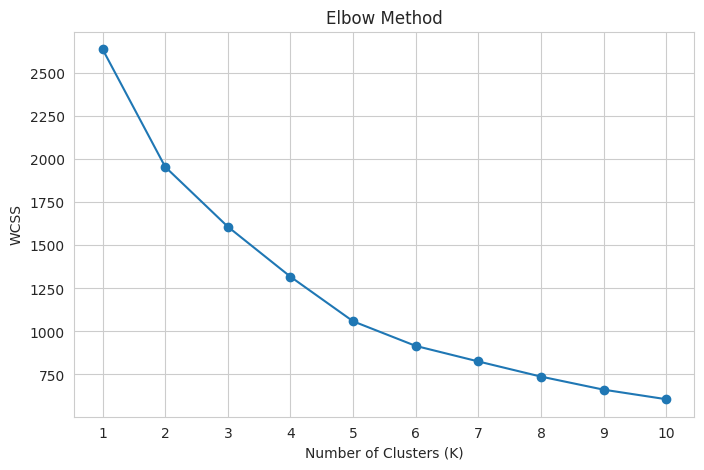

In [9]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.show()

In [10]:
# Set the optimal number of clusters
k = 3

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")
print(df["KMeans_Cluster"].value_counts().sort_index())

K-Means clustering completed!
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64


In [11]:
hierarchical = AgglomerativeClustering(
    n_clusters=k,
    linkage="ward"
)

df["Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

print("Hierarchical clustering completed!")
print(df["Hierarchical_Cluster"].value_counts().sort_index())

Hierarchical clustering completed!
Hierarchical_Cluster
0      6
1    281
2    153
Name: count, dtype: int64


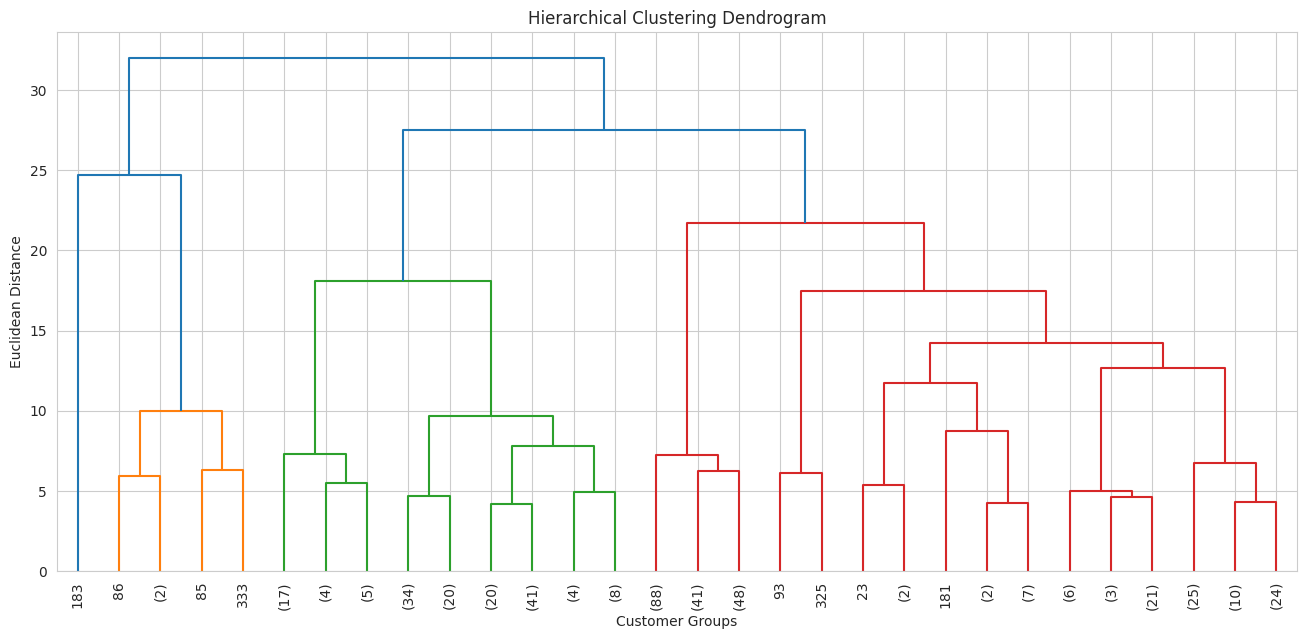

In [12]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(16, 7))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customer Groups")
plt.ylabel("Euclidean Distance")
plt.show()

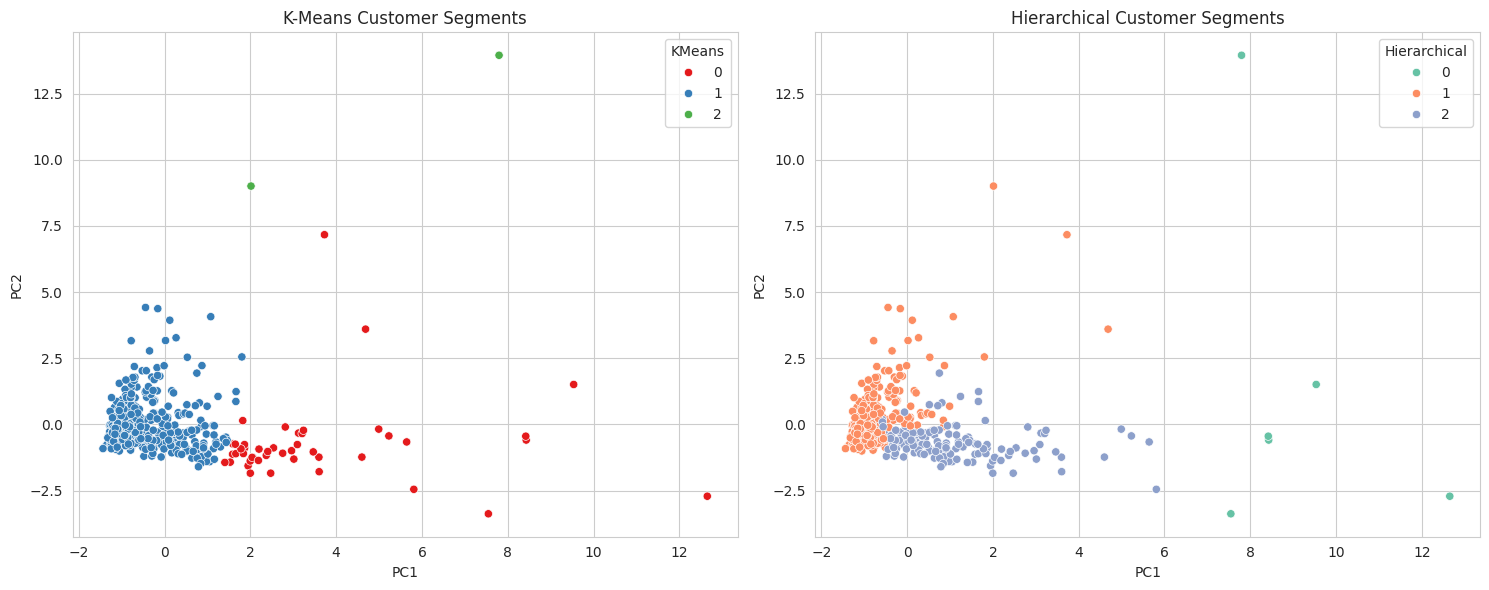

In [13]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "KMeans": df["KMeans_Cluster"],
    "Hierarchical": df["Hierarchical_Cluster"]
})

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="KMeans",
    palette="Set1",
    ax=axes[0]
)
axes[0].set_title("K-Means Customer Segments")

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Hierarchical",
    palette="Set2",
    ax=axes[1]
)
axes[1].set_title("Hierarchical Customer Segments")

plt.tight_layout()
plt.show()

      Algorithm  Silhouette Score
0       K-Means          0.548287
1  Hierarchical          0.264609


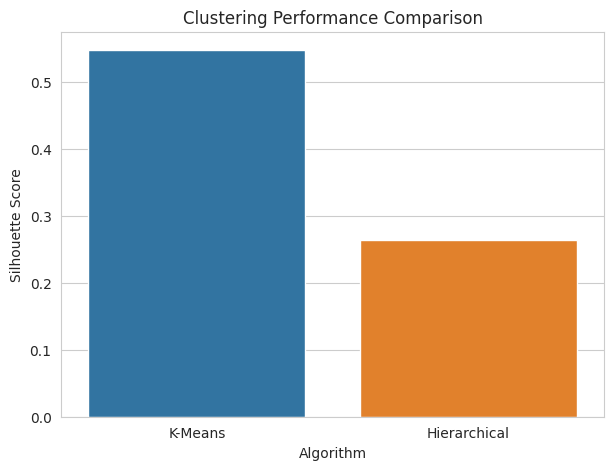

In [14]:
kmeans_silhouette = silhouette_score(
    X_scaled,
    df["KMeans_Cluster"]
)

hierarchical_silhouette = silhouette_score(
    X_scaled,
    df["Hierarchical_Cluster"]
)

comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical"],
    "Silhouette Score": [
        kmeans_silhouette,
        hierarchical_silhouette
    ]
})

print(comparison)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=comparison,
    x="Algorithm",
    y="Silhouette Score",
    hue="Algorithm",
    legend=False
)

plt.title("Clustering Performance Comparison")
plt.show()

In [15]:
cluster_profiles = df.groupby("KMeans_Cluster")[features].mean().round(2)

print("K-Means Customer Profiles:")
display(cluster_profiles)

print("\nNumber of customers in each cluster:")
print(df["KMeans_Cluster"].value_counts().sort_index())

K-Means Customer Profiles:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
KMeans_Cluster,,,,,,
0,10440.93,19386.42,28656.09,2190.24,13327.80,2374.20
1,12062.91,4115.10,5534.97,2940.68,1696.17,1299.11
2,34782.00,30367.00,16898.00,48701.50,755.50,26776.00



Number of customers in each cluster:
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64


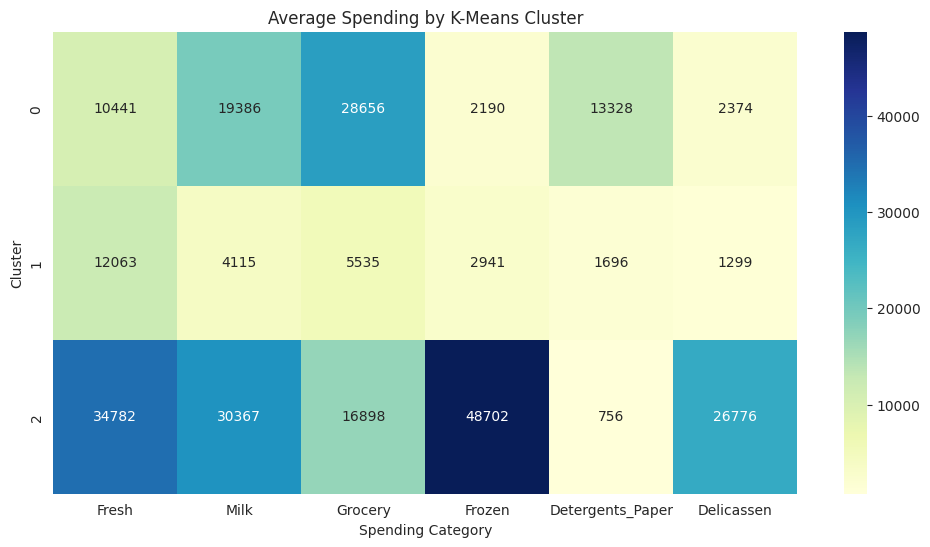

In [16]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    cluster_profiles,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Average Spending by K-Means Cluster")
plt.xlabel("Spending Category")
plt.ylabel("Cluster")
plt.show()